# 05 — Error analysis: where the forecast misses and why

Notebook 03 reports one number for 2025 (2.6% MAPE). This notebook breaks the error down to find *where* the model misses:

- by **hour of day**,
- by **day type**: regular weekday, weekend, statutory holiday, and the day after a holiday,
- by **sign** (does it over- or under-forecast?),
- and the **worst days** of the year.

Each slice is compared with the persistence baseline (same hour yesterday). The model is rebuilt exactly as in notebooks 03 and 04.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import holidays

from src.data import build_dataset
from src.features import make_features, FEATURES

warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")  # newer LightGBM versions only
d = make_features(build_dataset())
train, valid, test = d.loc[:"2023"], d.loc["2024"], d.loc["2025"]
train_full = d.loc[:"2024"]

params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)
gbm = lgb.LGBMRegressor(n_estimators=3000, **params)
gbm.fit(train[FEATURES], train["demand_mw"], eval_set=[(valid[FEATURES], valid["demand_mw"])],
        callbacks=[lgb.early_stopping(100, verbose=False)])
gbm_final = lgb.LGBMRegressor(n_estimators=int(gbm.best_iteration_ * 1.1), **params)
gbm_final.fit(train_full[FEATURES], train_full["demand_mw"])

r = test[["demand_mw", "hour", "dow", "month", "is_weekend", "is_holiday", "lag_24", "temp_day_mean"]].copy()
r["pred"] = gbm_final.predict(test[FEATURES])
r["err"] = r["pred"] - r["demand_mw"]                     # > 0 = over-forecast
r["ape"] = r["err"].abs() / r["demand_mw"] * 100
r["ape_persist"] = (r["lag_24"] - r["demand_mw"]).abs() / r["demand_mw"] * 100
print(f"2025 test MAPE: {r['ape'].mean():.2f}%  MAE: {r['err'].abs().mean():.0f} MW  (same model as notebook 03)")

2025 test MAPE: 2.63%  MAE: 448 MW  (same model as notebook 03)


## Day types

Statutory holidays come from the Ontario calendar used in the features. The *day after a holiday* gets its own group: its `lag_24` and `prev_day_*` features describe a low-demand holiday, so persistence-style features point the wrong way.

In [2]:
on_hols = holidays.Canada(subdiv="ON", years=[2024, 2025])
day = pd.Series(r.index.normalize(), index=r.index)
after_hol = day.map(lambda x: (x - pd.Timedelta(days=1)).date() in on_hols)
r["day_type"] = np.select(
    [r["is_holiday"] == 1, after_hol, r["is_weekend"] == 1],
    ["Holiday", "Day after holiday", "Weekend"], "Regular weekday")

order = ["Regular weekday", "Weekend", "Holiday", "Day after holiday"]
by_type = r.groupby("day_type").agg(
    days=("ape", lambda s: len(s) // 24), mape_model=("ape", "mean"), mape_persistence=("ape_persist", "mean"),
    mae_mw=("err", lambda e: e.abs().mean()), bias_mw=("err", "mean")).loc[order]
by_type.round(2)

,days,mape_model,mape_persistence,mae_mw,bias_mw
day_type,,,,,
Regular weekday,246,2.40,4.31,414.61,-240.32
Weekend,102,3.07,5.07,508.24,-399.61
Holiday,9,3.53,5.02,560.55,-386.15
Day after holiday,8,3.37,6.17,575.54,-558.48


## Error by hour of day

In [3]:
by_hour = r.groupby("hour").agg(mape_model=("ape", "mean"), mape_persistence=("ape_persist", "mean"),
                               bias_mw=("err", "mean"))
print(f"Lowest model MAPE:  hour {by_hour['mape_model'].idxmin():02d}:00 ({by_hour['mape_model'].min():.2f}%)")
print(f"Highest model MAPE: hour {by_hour['mape_model'].idxmax():02d}:00 ({by_hour['mape_model'].max():.2f}%)")
mid = by_hour.loc[10:15, "mape_model"].mean(); night = by_hour.loc[[0, 1, 2, 3, 4, 22, 23], "mape_model"].mean()
print(f"10:00-15:59 average: {mid:.2f}%   night (22:00-04:59) average: {night:.2f}%")
midday = r["hour"].between(10, 15); summer = r["month"].isin([6, 7, 8])
print(f"10:00-15:59 in June-August: {r.loc[midday & summer, 'ape'].mean():.2f}%   rest of year: {r.loc[midday & ~summer, 'ape'].mean():.2f}%")
by_hour.round(2)

Lowest model MAPE:  hour 00:00 (2.18%)
Highest model MAPE: hour 12:00 (3.19%)
10:00-15:59 average: 3.14%   night (22:00-04:59) average: 2.30%
10:00-15:59 in June-August: 3.55%   rest of year: 3.00%


,mape_model,mape_persistence,bias_mw
hour,,,
0,2.18,3.69,-218.09
1,2.32,3.74,-237.31
2,2.32,3.73,-233.70
3,2.34,3.82,-231.84
4,2.29,4.06,-235.18
5,2.42,5.02,-239.42
6,2.47,5.92,-292.80
7,2.60,5.90,-332.20
8,2.66,5.37,-347.08


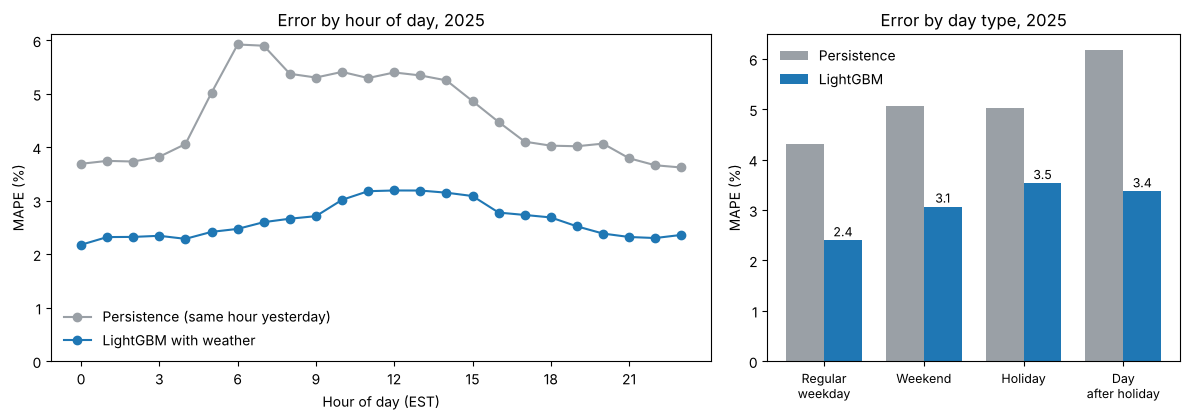

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
ax.plot(by_hour.index, by_hour["mape_persistence"], "o-", color="#9aa0a6", label="Persistence (same hour yesterday)")
ax.plot(by_hour.index, by_hour["mape_model"], "o-", color="#1f77b4", label="LightGBM with weather")
ax.set(xlabel="Hour of day (EST)", ylabel="MAPE (%)", title="Error by hour of day, 2025", xticks=range(0, 24, 3), ylim=(0, None))
ax.legend(frameon=False)
ax = axes[1]
x = np.arange(len(order)); w = 0.38
ax.bar(x - w/2, by_type["mape_persistence"], w, color="#9aa0a6", label="Persistence")
ax.bar(x + w/2, by_type["mape_model"], w, color="#1f77b4", label="LightGBM")
for i, v in enumerate(by_type["mape_model"]):
    ax.text(i + w/2, v + 0.08, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(x, [t.replace(" ", "\n", 1) if t != "Weekend" else t for t in order], fontsize=9)
ax.set(ylabel="MAPE (%)", title="Error by day type, 2025")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/error_by_hour_daytype_2025.png", dpi=130)
plt.show()

## Over- or under-forecast?

A well-calibrated model should have a mean error near zero. The table above already shows a negative bias in every group, so look at it directly, by month.

In [5]:
bias = r["err"].mean()
print(f"Mean error over 2025: {bias:+.0f} MW; {(r['err'] < 0).mean() * 100:.0f}% of hours are under-forecast")
growth = d.loc["2025", "demand_mw"].mean() / d.loc["2024", "demand_mw"].mean() - 1
print(f"Average demand 2025 vs 2024: {growth * 100:+.1f}%")
by_month = r.groupby("month").agg(bias_mw=("err", "mean"), mape_model=("ape", "mean"))
# Diagnostic only (uses 2025 to pick the shift, so not a valid forecast): what removing the level offset would buy
shifted = ((r["pred"] - bias - r["demand_mw"]).abs() / r["demand_mw"]).mean() * 100
print(f"Diagnostic: MAPE if the 2025 mean offset were removed: {shifted:.2f}% (vs {r['ape'].mean():.2f}%)")
by_month.round(1).T

Mean error over 2025: -295 MW; 76% of hours are under-forecast
Average demand 2025 vs 2024: +4.0%
Diagnostic: MAPE if the 2025 mean offset were removed: 2.21% (vs 2.63%)


month,1,2,3,4,5,6,7,8,9,10,11,12
bias_mw,-300.2,-353.4,-190.5,-118.0,-239.5,-247.1,-481.5,-371.5,-325.2,-276.6,-312.1,-329.2
mape_model,2.2,2.6,2.6,2.6,2.3,3.0,3.3,3.0,2.4,2.6,2.4,2.6


## Holidays one by one

In [6]:
rows = []
for date, name in sorted(on_hols.items()):
    if date.year != 2025:
        continue
    for label, dd in [(name, pd.Timestamp(date)), ("  day after", pd.Timestamp(date) + pd.Timedelta(days=1))]:
        if label == "  day after" and dd.date() in on_hols:
            continue  # e.g. Boxing Day follows Christmas: listed as a holiday itself
        s = r.loc[str(dd.date())]
        if len(s):
            rows.append(dict(date=dd.date(), day=label, weekday=dd.day_name()[:3],
                             mape_model=s["ape"].mean(), mape_persistence=s["ape_persist"].mean(), bias_mw=s["err"].mean()))
pd.DataFrame(rows).set_index("date").round(2)

,day,weekday,mape_model,mape_persistence,bias_mw
date,,,,,
2025-01-01,New Year's Day,Wed,2.67,3.65,-353.91
2025-01-02,day after,Thu,3.04,8.53,-498.07
2025-02-17,Family Day,Mon,1.71,3.04,170.79
2025-02-18,day after,Tue,4.47,7.17,-856.24
2025-04-18,Good Friday,Fri,4.29,8.89,221.20
2025-04-19,day after,Sat,2.64,3.20,-310.28
2025-05-19,Victoria Day,Mon,3.88,3.59,-501.21
2025-05-20,day after,Tue,2.89,6.83,-416.70
2025-07-01,Canada Day,Tue,3.34,4.26,-585.01


## The 10 worst days of 2025

In [7]:
daily = r.resample("D").agg({"ape": "mean", "ape_persist": "mean", "err": "mean", "temp_day_mean": "first", "day_type": "first"})
daily["weekday"] = daily.index.day_name().str[:3]
worst = daily.sort_values("ape", ascending=False).head(10)
print(f"Worst 10 days: {(worst['err'] < 0).sum()} under-forecast; "
      f"{worst['day_type'].isin(['Weekend', 'Holiday']).sum()} are weekends or holidays; "
      f"{(worst['temp_day_mean'] >= 23).sum()} have a daily mean of 23 °C or more")
worst.rename(columns={"ape": "mape_model", "ape_persist": "mape_persistence", "err": "bias_mw"}).round(2)

Worst 10 days: 9 under-forecast; 8 are weekends or holidays; 5 have a daily mean of 23 °C or more


,mape_model,mape_persistence,bias_mw,temp_day_mean,day_type,weekday
datetime,,,,,,
2025-12-26,9.17,8.94,-1657.09,-4.95,Holiday,Fri
2025-08-10,8.19,2.73,-1702.12,26.90,Weekend,Sun
2025-06-22,8.01,15.51,-1572.34,27.71,Weekend,Sun
2025-07-26,7.05,8.25,-1370.40,23.69,Weekend,Sat
2025-02-02,6.26,2.95,-1157.70,-5.86,Weekend,Sun
2025-08-09,6.16,2.88,-1285.69,25.89,Weekend,Sat
2025-09-21,5.74,6.48,-888.69,18.40,Weekend,Sun
2025-07-25,5.29,6.83,-1013.97,26.01,Regular weekday,Fri
2025-06-30,5.28,6.79,877.07,22.65,Regular weekday,Mon


## Takeaways (2025 test year)

- **The model beats persistence in every hour and every day type**, but its error is not flat. It is lowest overnight (2.30% MAPE, 22:00–04:59) and highest in the middle of the day (3.14% for 10:00–15:59, peaking at 3.19% at noon). The midday misses are concentrated in summer: 3.55% for 10:00–15:59 in June–August against 3.00% the rest of the year.
- **Weekends and holidays are harder.** MAPE is 2.40% on regular weekdays, 3.07% on weekends and 3.53% on statutory holidays. On the day *after* a holiday, persistence breaks down (6.17%) because yesterday was a low-demand day; the model holds at 3.37% thanks to the calendar features, but its bias there is the largest of any group (−558 MW). Boxing Day was the worst day of 2025 (9.17%, −1,657 MW): it is flagged as a holiday, yet actual demand was far above what the model expects for one.
- **The model systematically under-forecasts 2025.** The mean error is −295 MW and 76% of hours are under-forecast, with a negative bias in every month. Average demand grew 4.0% from 2024 to 2025, and tree models cannot predict above the levels seen in training. As a diagnostic only, removing that constant offset would cut MAPE from 2.63% to 2.21%, so handling load growth (e.g. a trend term or forecasting the change from last year) is the single biggest available fix.
- **The worst days are hot weekends.** Of the 10 worst days, 9 are under-forecast, 8 are weekends or holidays and 5 have a daily mean of 23 °C or more. Weekend heat waves are rare in the training data and combine the two weakest slices above.